# EDA: `DDoS-HTTP_Flood-.pcap.csv` (um pedaço da CIC-IoT2023)

Ticket: `docs/issues/10-eda-cic-iot2023-ddos-http-flood.md`.

**Escopo e limites.** Este notebook analisa **um único arquivo** de uma base de 46,7 milhões de registros (valor declarado na planilha, não medido). O arquivo **não tem coluna de rótulo**: a classe (`DDoS-HTTP_Flood`) só aparece no nome do arquivo. Portanto não há baseline supervisionado nem medida de separabilidade, e nada aqui diz como este ataque se compara aos outros. O que dá para fazer: entender o esquema, a coerência dos dados, as armadilhas e o custo por registro.

Fonte: CIC/UNB, Neto et al., Sensors 2023 (DOI 10.3390/s23135941). Detalhes do esquema e das divergências com a página oficial em `docs/cic-iot2023-arquivos-csv.md`.

In [1]:
from pathlib import Path
import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

T0 = time.time()
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
ROOT = Path.cwd().parent
F = ROOT / "data/raw/cic-iot2023/DDoS-HTTP_Flood-.pcap.csv"
df = pd.read_csv(F)

## 1. Esquema e qualidade

In [2]:
print("linhas:", len(df), "| colunas:", df.shape[1], "| tamanho em disco: %.2f MB" % (F.stat().st_size / 1e6))
print("tipos:", df.dtypes.value_counts().to_dict())
print("nulos:", int(df.isna().sum().sum()), "| linhas duplicadas:", int(df.duplicated().sum()), "| valores infinitos:", int(np.isinf(df.to_numpy(dtype=float)).sum()))
nun = df.nunique()
print("colunas constantes:", nun[nun == 1].index.tolist())
print("colunas com 2 a 5 valores distintos:", nun[(nun > 1) & (nun <= 5)].to_dict())
print("colunas inteiras:", df.select_dtypes("int64").columns.tolist())
print("há coluna de rótulo?", [c for c in df.columns if c.lower() in ("label", "class", "attack")] or "não")

linhas: 28790 | colunas: 39 | tamanho em disco: 6.45 MB
tipos: {dtype('float64'): 30, dtype('int64'): 9}
nulos: 0 | linhas duplicadas: 0 | valores infinitos: 0
colunas constantes: ['Telnet', 'SMTP', 'IRC']
colunas com 2 a 5 valores distintos: {'Protocol Type': 3}
colunas inteiras: ['Protocol Type', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'Tot sum', 'Min', 'Max', 'Number']
há coluna de rótulo? não


### 1.1 Coerência interna

Hipóteses lidas nas primeiras linhas, testadas aqui em vez de assumidas. Cada verificação informa a fração de linhas que a cumpre; só as regras estruturais óbvias interrompem a execução se falharem.

In [3]:
frac_cols = [c for c in df.columns if c.endswith("_flag_number")] + ["HTTP", "HTTPS", "DNS", "Telnet", "SMTP", "SSH", "IRC", "TCP", "UDP", "DHCP", "ARP", "ICMP", "IGMP", "IPv", "LLC"]
assert df[frac_cols].min().min() >= 0 and df[frac_cols].max().max() <= 1, "fração fora de [0, 1]"
assert (df.Min <= df.AVG + 1e-9).all() and (df.AVG <= df.Max + 1e-9).all(), "Min <= AVG <= Max violado"
print("regras estruturais OK: frações em [0, 1] e Min <= AVG <= Max em todas as linhas")

def cumpre(nome, ok):
    print(f"{nome:58s} {ok.mean():7.2%}  ({int((~ok).sum()):,} linhas fora)")

n = df.Number
cumpre("Variance == Std^2 (tolerância relativa 1e-6)", np.isclose(df.Variance, df.Std ** 2, rtol=1e-6, atol=1e-9))
cumpre("Tot size == AVG", np.isclose(df["Tot size"], df.AVG))
cumpre("Tot sum == AVG * Number", np.isclose(df["Tot sum"], df.AVG * n, rtol=1e-6))
cumpre("IPv == LLC", df.IPv == df.LLC)
ri = df.Rate * df.IAT
cumpre("Rate * IAT == 1 exato (tolerância relativa 1e-6)", pd.Series(np.isclose(ri, 1, rtol=1e-6)))
cumpre("Rate * IAT == 1 dentro de 1%", (ri - 1).abs() < .01)
cumpre("Rate * IAT == 1 dentro de 10%", (ri - 1).abs() < .1)
cumpre("ARP == 1 - IPv (a 0,01)", np.isclose(df.ARP, 1 - df.IPv, atol=.0101))
cumpre("contagens de flags <= Number (ack, syn, fin, rst)", (df[["ack_count", "syn_count", "fin_count", "rst_count"]].le(n, axis=0)).all(axis=1))
for f in ["ack", "syn", "fin", "rst"]:
    cumpre(f"{f}_flag_number == {f}_count / Number (a 0,01)", np.isclose(df[f + "_flag_number"], df[f + "_count"] / n, atol=0.0101))
print("linhas com IAT == 0:", int((df.IAT == 0).sum()), "| com Rate == 0:", int((df.Rate == 0).sum()))

regras estruturais OK: frações em [0, 1] e Min <= AVG <= Max em todas as linhas
Variance == Std^2 (tolerância relativa 1e-6)               100.00%  (0 linhas fora)
Tot size == AVG                                            100.00%  (0 linhas fora)
Tot sum == AVG * Number                                    100.00%  (0 linhas fora)
IPv == LLC                                                 100.00%  (0 linhas fora)
Rate * IAT == 1 exato (tolerância relativa 1e-6)             6.85%  (26,817 linhas fora)
Rate * IAT == 1 dentro de 1%                                87.17%  (3,693 linhas fora)
Rate * IAT == 1 dentro de 10%                               96.97%  (873 linhas fora)
ARP == 1 - IPv (a 0,01)                                    100.00%  (0 linhas fora)
contagens de flags <= Number (ack, syn, fin, rst)          100.00%  (0 linhas fora)
ack_flag_number == ack_count / Number (a 0,01)             100.00%  (0 linhas fora)
syn_flag_number == syn_count / Number (a 0,01)             100.00%  (

## 2. Distribuições

In [4]:
print("Number (provável número de pacotes por janela):")
print(df.Number.value_counts().head(6).to_string())
print(f"linhas com Number < 100: {(df.Number < 100).sum()} ({(df.Number < 100).mean():.2%})")
d = df.drop(columns=["Telnet", "SMTP", "IRC"]).describe(percentiles=[.01, .5, .99]).T
d["max/mediana"] = d["max"] / d["50%"].replace(0, np.nan)
d["assimetria"] = df.drop(columns=["Telnet", "SMTP", "IRC"]).skew()
print(d[["min", "1%", "50%", "99%", "max", "max/mediana", "assimetria"]].round(3).to_string())

Number (provável número de pacotes por janela):
Number
100    28729
73         3
40         3
51         2
49         2
25         2
linhas com Number < 100: 61 (0.21%)
                    min        1%        50%         99%          max   max/mediana  assimetria
Header_Length      1.00    19.360     33.640      40.000       53.640  1.595000e+00      -1.181
Protocol Type      0.00     6.000      6.000       6.000       17.000  2.833000e+00      15.644
Time_To_Live       7.03    62.080     64.820      86.930      207.210  3.197000e+00       7.354
Rate               0.00    60.917    811.011   41945.727   699050.667  8.619500e+02      19.205
fin_flag_number    0.00     0.000      0.060       0.440        0.970  1.616700e+01       2.411
syn_flag_number    0.00     0.000      0.260       1.000        1.000  3.846000e+00       1.214
rst_flag_number    0.00     0.000      0.090       0.940        1.000  1.111100e+01       2.118
psh_flag_number    0.00     0.000      0.110       0.410       

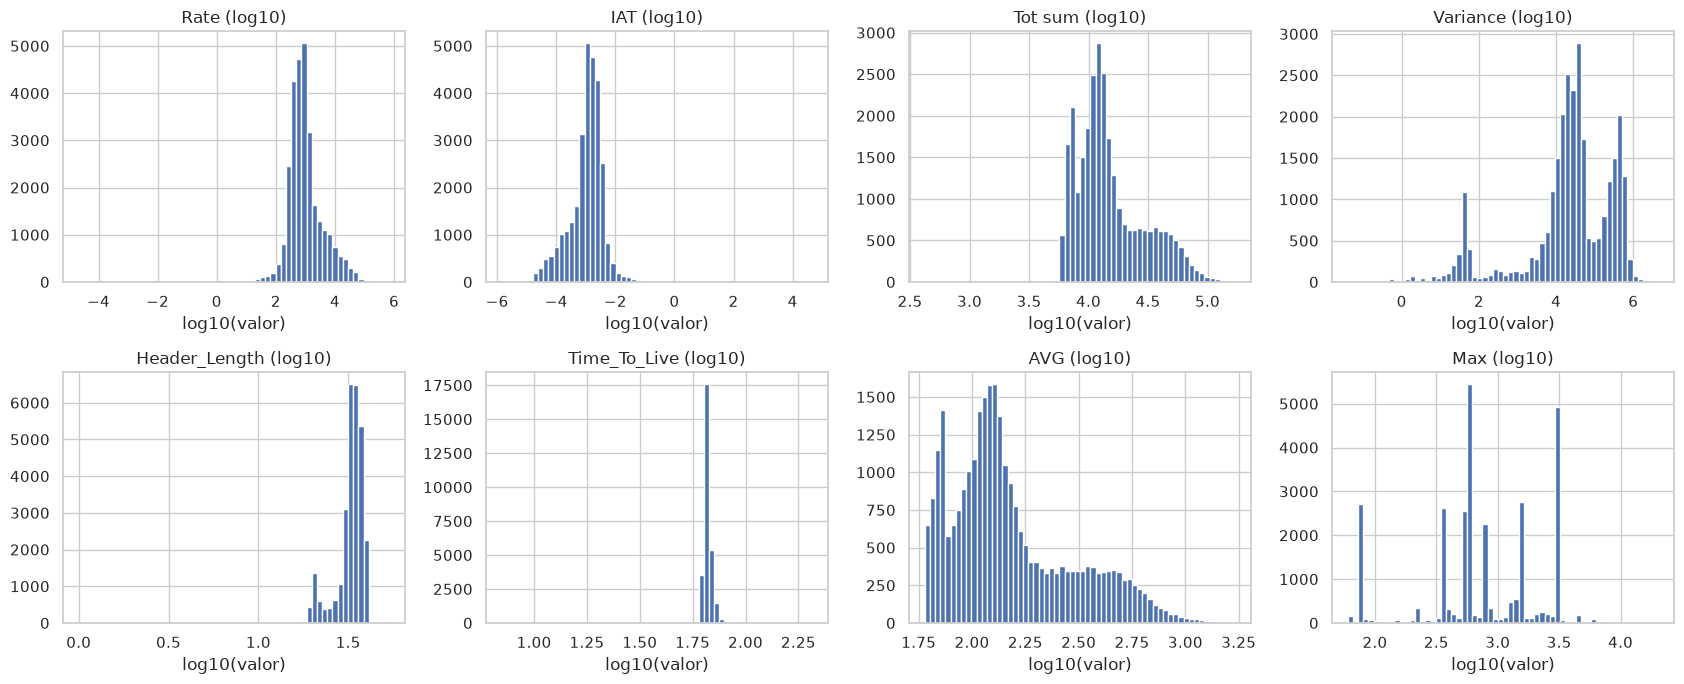

In [5]:
vars_ = ["Rate", "IAT", "Tot sum", "Variance", "Header_Length", "Time_To_Live", "AVG", "Max"]
fig, ax = plt.subplots(2, 4, figsize=(17, 7))
for a, v in zip(ax.ravel(), vars_):
    x = df[v][df[v] > 0]
    a.hist(np.log10(x), bins=60); a.set(title=v + " (log10)", xlabel="log10(valor)")
plt.tight_layout(); plt.show()

In [6]:
print("assimetria alta (> 5), candidatas a log/clipping:", df.drop(columns=["Telnet", "SMTP", "IRC"]).skew().loc[lambda s: s.abs() > 5].round(1).to_dict())
q = df[["Rate", "IAT"]].quantile([.5, .99, .999, 1]).round(4)
print(q.to_string())
print("linhas com Rate acima de 100.000:", int((df.Rate > 1e5).sum()))
print("linhas com IAT > 1 s:", int((df.IAT > 1).sum()), "| > 10 s:", int((df.IAT > 10).sum()), "| > 1000 s:", int((df.IAT > 1000).sum()))
print(df.nlargest(4, "IAT")[["IAT", "Rate", "Number", "Tot sum", "Header_Length"]].round(4).to_string())

assimetria alta (> 5), candidatas a log/clipping: {'Protocol Type': 15.6, 'Time_To_Live': 7.4, 'Rate': 19.2, 'ece_flag_number': 71.3, 'cwr_flag_number': 64.7, 'HTTPS': 6.6, 'DNS': 14.1, 'SSH': 16.4, 'TCP': -5.9, 'UDP': 6.8, 'DHCP': 35.3, 'ARP': 14.2, 'ICMP': 8.5, 'IGMP': 12.3, 'IPv': -14.2, 'LLC': -14.2, 'Min': 94.5, 'IAT': 169.7, 'Number': -25.9}
              Rate         IAT
0.500     811.0107      0.0012
0.990   41945.7274      0.0166
0.999  120021.5008      0.0491
1.000  699050.6667  46665.2123
linhas com Rate acima de 100.000: 37
linhas com IAT > 1 s: 8 | > 10 s: 4 | > 1000 s: 1
              IAT    Rate  Number  Tot sum  Header_Length
16487  46665.2123  0.0000     100     9868          18.28
15006    102.6026  0.0097     100    57705          30.08
21034     12.6216  0.0792     100    14634          23.16
27239     12.6188  0.0792     100    11458          18.68


## 3. Redundância

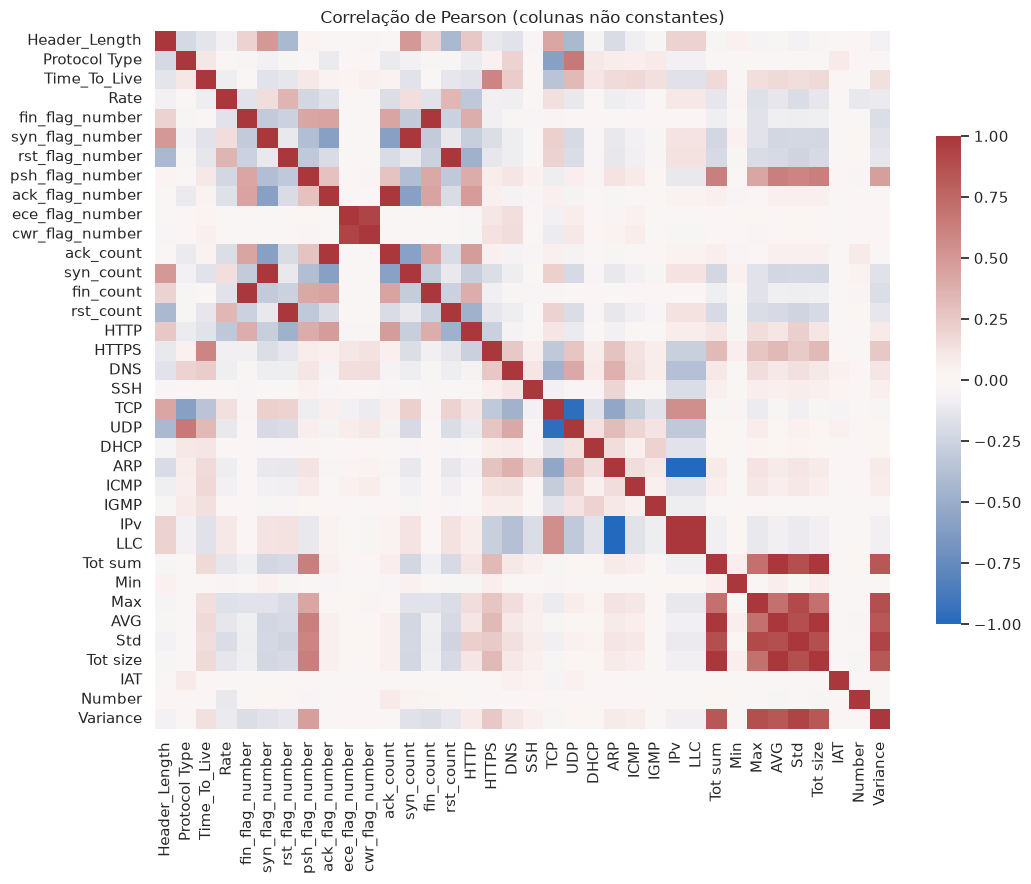

pares com |r| > 0,95: 11
AVG              Tot size     1.0000
IPv              LLC          1.0000
ARP              LLC         -1.0000
                 IPv         -1.0000
rst_flag_number  rst_count    0.9993
syn_flag_number  syn_count    0.9992
fin_flag_number  fin_count    0.9972
Tot sum          AVG          0.9964
                 Tot size     0.9964
ack_flag_number  ack_count    0.9947
TCP              UDP         -0.9625
pares de colunas idênticas: [('IPv', 'LLC'), ('AVG', 'Tot size')]


In [7]:
num = df.drop(columns=["Telnet", "SMTP", "IRC"])
corr = num.corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws=dict(shrink=.7))
ax.set_title("Correlação de Pearson (colunas não constantes)")
plt.tight_layout(); plt.show()
par = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
alto = par[par.abs() > .95].sort_values(key=abs, ascending=False)
print(f"pares com |r| > 0,95: {len(alto)}")
print(alto.round(4).to_string())
ident = [(a, b) for i, a in enumerate(num.columns) for b in num.columns[i + 1:] if np.allclose(num[a], num[b])]
print("pares de colunas idênticas:", ident)

## 4. Ordem das linhas

Se as linhas fossem embaralhadas, a autocorrelação de lag 1 seria próxima de zero (limite de 95%: cerca de ±2/√n). Valores altos indicam que a ordem do arquivo carrega estrutura (janelas consecutivas do mesmo fluxo).

limite de ruído (95%): ±0.0118
autocorrelação lag 1 (maiores):
HTTP               0.967
HTTPS              0.825
Header_Length      0.719
Std                0.707
UDP                0.679
TCP                0.675
Tot sum            0.666
AVG                0.666
Tot size           0.666
ack_flag_number    0.665
colunas com |autocorr| acima do ruído: 33 de 36
mesma estatística após embaralhar as linhas (controle): máximo |autocorr| = 0.0107


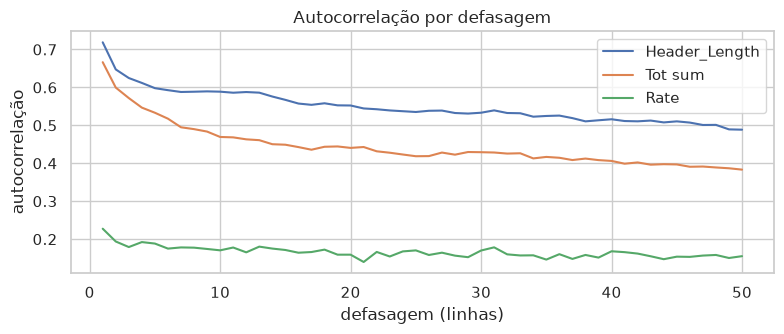

In [8]:
cols = num.columns
ac = pd.Series({c: num[c].autocorr(1) for c in cols}).sort_values(ascending=False)
lim = 2 / np.sqrt(len(df))
print(f"limite de ruído (95%): ±{lim:.4f}")
print("autocorrelação lag 1 (maiores):")
print(ac.head(10).round(3).to_string())
print(f"colunas com |autocorr| acima do ruído: {int((ac.abs() > lim).sum())} de {len(ac)}")
emb = num.sample(frac=1, random_state=0).reset_index(drop=True)
print("mesma estatística após embaralhar as linhas (controle): máximo |autocorr| = %.4f" % pd.Series({c: emb[c].autocorr(1) for c in cols}).abs().max())
fig, ax = plt.subplots(figsize=(8, 3.5))
for c in ["Header_Length", "Tot sum", "Rate"]:
    ax.plot(range(1, 51), [num[c].autocorr(k) for k in range(1, 51)], label=c)
ax.set(xlabel="defasagem (linhas)", ylabel="autocorrelação", title="Autocorrelação por defasagem"); ax.legend()
plt.tight_layout(); plt.show()

### 4.1 Segmentos

As 61 linhas com `Number < 100` aparecem espalhadas pelo arquivo, não só no fim. **Hipótese:** cada uma fecha um segmento (por exemplo, o fim de um trecho de captura, em que a última janela sai incompleta), e o arquivo é a concatenação de cerca de 60 segmentos. Teste: se os segmentos forem internamente homogêneos, a variância *entre* segmentos será muito maior do que a esperada ao acaso.

In [9]:
curta = df.Number < 100
seg = curta.shift(fill_value=False).cumsum()
tam = seg.value_counts().sort_index()
print("segmentos:", len(tam), "| linhas por segmento: mínimo", tam.min(), "mediana", int(tam.median()), "máximo", tam.max())
print("posição das linhas curtas (primeiras 8):", df.index[curta][:8].tolist(), "| última linha é curta:", bool(curta.iloc[-1]))

def eta2(x, g):
    m = x.groupby(g).transform("mean")
    return ((m - x.mean()) ** 2).sum() / ((x - x.mean()) ** 2).sum()

nc = num.columns.difference(["Number"])
e = pd.Series({c: eta2(num[c], seg) for c in nc}).sort_values(ascending=False)
rng = np.random.default_rng(0)
ctrl = pd.Series({c: eta2(num[c], pd.Series(rng.permutation(seg.to_numpy()))) for c in nc})
print("eta2 entre segmentos (fração da variância explicada pelo segmento); ao acaso seria cerca de %.4f" % ((len(tam) - 1) / (len(df) - 1)))
print(e.head(8).round(3).to_string())
print("mediana entre as colunas: %.3f | controle com segmentos embaralhados (mediana): %.4f" % (e.median(), ctrl.median()))

segmentos: 61 | linhas por segmento: mínimo 68 mediana 297 máximo 1146
posição das linhas curtas (primeiras 8): [927, 1182, 1441, 1686, 1881, 2158, 2805, 3102] | última linha é curta: True
eta2 entre segmentos (fração da variância explicada pelo segmento); ao acaso seria cerca de 0.0021
HTTP               0.890
Std                0.543
Header_Length      0.447
AVG                0.427
Tot size           0.427
Tot sum            0.426
rst_flag_number    0.421
rst_count          0.421
mediana entre as colunas: 0.239 | controle com segmentos embaralhados (mediana): 0.0020


## 5. Heterogeneidade: o arquivo é só tráfego HTTP?

In [10]:
cobre = ["HTTP", "HTTPS", "TCP", "UDP", "DNS", "ARP", "ICMP", "DHCP", "SSH"]
print(df[cobre].describe(percentiles=[.5, .9]).loc[["mean", "50%", "90%", "max"]].round(3).to_string())
dom = (df.TCP >= .9) & (df.HTTP >= .5)
print(f"linhas com TCP >= 0,9 e HTTP >= 0,5 (padrão dominante): {dom.sum():,} ({dom.mean():.1%})")
print(f"linhas fora do padrão: {(~dom).sum():,}  | HTTP < 0,1: {(df.HTTP < .1).sum():,} | ARP >= 0,5: {(df.ARP >= .5).sum():,} | UDP >= 0,5: {(df.UDP >= .5).sum():,} | DNS >= 0,5: {(df.DNS >= .5).sum():,}")

       HTTP  HTTPS    TCP    UDP    DNS    ARP   ICMP  DHCP   SSH
mean  0.778  0.032  0.964  0.027  0.005  0.007  0.002  0.00  0.00
50%   0.940  0.010  0.980  0.010  0.000  0.000  0.000  0.00  0.00
90%   0.990  0.060  1.000  0.060  0.020  0.020  0.010  0.00  0.00
max   1.000  1.000  1.000  0.870  0.590  0.920  0.230  0.21  0.06
linhas com TCP >= 0,9 e HTTP >= 0,5 (padrão dominante): 22,660 (78.7%)
linhas fora do padrão: 6,130  | HTTP < 0,1: 4,634 | ARP >= 0,5: 1 | UDP >= 0,5: 102 | DNS >= 0,5: 2


In [11]:
g = df.groupby(seg).agg(linhas=("HTTP", "size"), HTTP=("HTTP", "median"), TCP=("TCP", "median"), syn=("syn_flag_number", "median"), rst=("rst_flag_number", "median"), ack=("ack_flag_number", "median"))
sem_http = g[g.HTTP < .1]
baixo = df.HTTP < .1
print(f"segmentos com HTTP mediano < 0,1: {len(sem_http)} de {len(g)} ({int(sem_http.linhas.sum()):,} linhas, {sem_http.linhas.sum() / len(df):.1%} do arquivo)")
print(f"das {baixo.sum():,} linhas com HTTP < 0,1, {int(baixo[seg.isin(sem_http.index)].sum()):,} ({baixo[seg.isin(sem_http.index)].sum() / baixo.sum():.0%}) estão nesses segmentos")
print(sem_http.round(2).to_string())
print("mediana dos demais segmentos:", g[g.HTTP >= .1][["HTTP", "TCP", "syn", "rst", "ack"]].median().round(2).to_dict())

segmentos com HTTP mediano < 0,1: 6 de 61 (4,386 linhas, 15.2% do arquivo)
das 4,634 linhas com HTTP < 0,1, 4,267 (92%) estão nesses segmentos
        linhas  HTTP   TCP   syn   rst   ack
Number                                      
4          195   0.0  0.99  0.31  0.01  0.73
13         850   0.0  1.00  0.55  0.36  0.44
29        1109   0.0  1.00  0.53  0.45  0.47
33         883   0.0  1.00  0.48  0.45  0.51
40         203   0.0  0.99  0.27  0.00  0.73
51        1146   0.0  1.00  0.54  0.45  0.46
mediana dos demais segmentos: {'HTTP': 0.95, 'TCP': 0.98, 'syn': 0.26, 'rst': 0.1, 'ack': 0.79}


variância explicada pelas 5 primeiras componentes: [0.231, 0.131, 0.092, 0.076, 0.057] | acumulada: 0.587


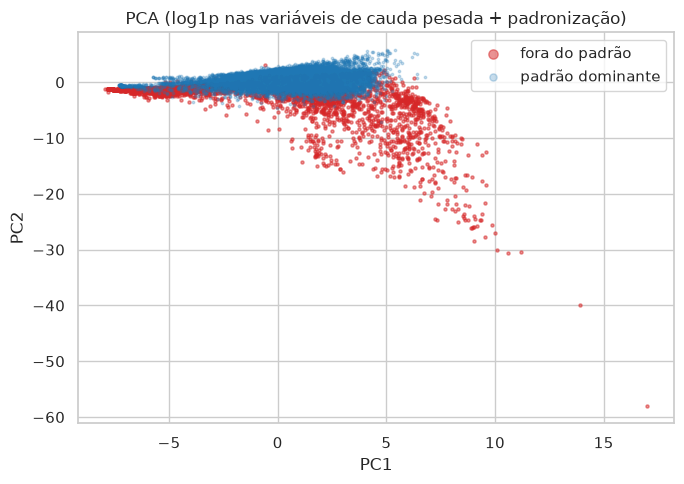

In [12]:
pesadas = ["Rate", "IAT", "Tot sum", "Variance", "Std", "Max", "AVG", "Tot size", "Min"]
X = num.copy(); X[pesadas] = np.log1p(X[pesadas])
Z = StandardScaler().fit_transform(X)
pca = PCA(n_components=5).fit(Z)
P = pca.transform(Z)
print("variância explicada pelas 5 primeiras componentes:", pca.explained_variance_ratio_.round(3).tolist(), "| acumulada: %.3f" % pca.explained_variance_ratio_.sum())
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(P[~dom, 0], P[~dom, 1], s=5, alpha=.5, label="fora do padrão", color="tab:red")
ax.scatter(P[dom, 0], P[dom, 1], s=3, alpha=.25, label="padrão dominante", color="tab:blue")
ax.set(xlabel="PC1", ylabel="PC2", title="PCA (log1p nas variáveis de cauda pesada + padronização)"); ax.legend(markerscale=3)
plt.tight_layout(); plt.show()

## 6. Escala: custo por registro e extrapolação

**Atenção:** o que segue extrapola de **um pedaço** de 28.790 linhas para os 46.686.579 registros declarados na planilha, supondo largura de linha semelhante em todos os arquivos. É uma ordem de grandeza, não uma medida.

In [13]:
N_TOTAL = 46_686_579
b_csv = F.stat().st_size / len(df)
mem64 = df.memory_usage(deep=True).sum() / len(df)
f32 = df.astype({c: "float32" for c in df.select_dtypes("float64").columns} | {c: "int32" for c in df.select_dtypes("int64").columns})
mem32 = f32.memory_usage(deep=True).sum() / len(df)
tab = pd.DataFrame({"bytes_por_registro": [b_csv, mem64, mem32]}, index=["CSV em disco", "pandas (float64/int64)", "pandas (float32/int32)"])
tab["medido_no_arquivo_MB"] = [F.stat().st_size / 1e6, mem64 * len(df) / 1e6, mem32 * len(df) / 1e6]
tab["EXTRAPOLADO_para_46,7M_registros_GB"] = tab.bytes_por_registro * N_TOTAL / 1e9
print(tab.round(2).to_string())
print("RAM total da máquina: ~15 GB, com cerca de 4 GB livres no início do trabalho (AGENTS.md)")

                        bytes_por_registro  medido_no_arquivo_MB  EXTRAPOLADO_para_46,7M_registros_GB
CSV em disco                        224.03                  6.45                                10.46
pandas (float64/int64)              312.00                  8.98                                14.57
pandas (float32/int32)              156.00                  4.49                                 7.28
RAM total da máquina: ~15 GB, com cerca de 4 GB livres no início do trabalho (AGENTS.md)


---
## 7. O que sabemos e o que não sabemos

### Sabemos (medido neste arquivo)
- **Forma e qualidade:** 28.790 linhas, 39 colunas (30 `float64`, 9 `int64`), 6,45 MB; 0 nulos, 0 duplicadas, 0 infinitos. Três colunas constantes (`Telnet`, `SMTP`, `IRC`). **Não há coluna de rótulo.**
- **Coerência:** valem em 100% das linhas `Variance = Std²`, `Tot size = AVG`, `Tot sum = AVG × Number`, `IPv = LLC`, `ARP = 1 − IPv`, `*_flag_number = *_count / Number` (a 0,01) e `contagem de flag ≤ Number`. `Rate × IAT ≈ 1`: dentro de 1% em 87,2% das linhas e de 10% em 97,0%, exato em só 6,85% (a diferença de definição não está documentada).
- **Redundância:** 11 pares com |r| > 0,95. Pelo menos 5 das 39 colunas podem sair sem perda de informação (3 constantes e 2 cópias exatas: `LLC` e `Tot size`), e várias outras são derivadas de outras.
- **`Number`:** vale 100 em 99,79% das linhas; as 61 linhas com valor menor ficam espalhadas pelo arquivo (primeiras posições: 927, 1182, 1441…) e a última linha é uma delas.
- **Estrutura em segmentos:** se cada linha curta fecha um segmento, são **61 segmentos** de 68 a 1.146 linhas (mediana 297). O segmento explica 89% da variância de `HTTP` e, em mediana, 24% da variância das colunas, contra ~0,2% ao acaso (controle com segmentos embaralhados: 0,2%).
- **Ordem sequencial:** a autocorrelação de lag 1 chega a 0,967 (`HTTP`); 33 de 36 colunas ficam acima do ruído (±0,012), e o controle embaralhado dá no máximo 0,011.
- **Caudas pesadas:** `Rate` vai a 699.051 (862 vezes a mediana); `IAT` tem 8 linhas acima de 1 s e uma de 46.665 s (cerca de 13 horas), que provavelmente marca uma lacuna entre trechos da captura (hipótese). 19 colunas têm assimetria acima de 5 em módulo.
- **Heterogeneidade:** 78,7% das linhas são TCP ≥ 0,9 com HTTP ≥ 0,5. As 4.634 linhas com HTTP < 0,1 (16,1%) concentram-se em **6 segmentos inteiros** (4.386 linhas, 15,2% do arquivo; neles estão 4.267 das 4.634 linhas, 92%), quase só TCP, com SYN, RST e ACK em proporções altas e HTTP mediano 0.
- **Escala (medida no arquivo, extrapolação para 46.686.579 registros):** 224 bytes por registro no CSV (~10,5 GB), 312 bytes no pandas com `float64`/`int64` (~14,6 GB) e 156 bytes com `float32`/`int32` (~7,3 GB).

### Não sabemos
- **O rótulo.** A classe vem do nome do arquivo. Os 6 segmentos sem HTTP podem ser outra fase do ataque ou outro tráfego da captura; não dá para saber daqui, e o rótulo por nome de arquivo pode ser ruidoso nesses trechos.
- **O significado exato** de `Number` (provável número de pacotes por janela) e dos segmentos; ambos são hipóteses sustentadas pelos números, não documentadas.
- **Representatividade.** Um arquivo de uma classe não diz como é o restante da base, nem como o ataque se distingue dos outros.
- **A origem das diferenças** entre as 39 colunas destes arquivos e as 46 features descritas na página oficial.
- **O tamanho real da base.** A extrapolação supõe a mesma largura de linha em todos os arquivos.

### Implicações para o trabalho seguinte (propostas, a validar)
1. **Nunca dividir treino/teste por linha.** Com autocorrelação de 0,97 e segmentos homogêneos, linhas vizinhas dos dois lados inflariam qualquer métrica; dividir por segmento (ou por arquivo) é o mínimo.
2. **Limpeza barata:** remover as colunas constantes e as cópias exatas; aplicar log (ou limitar) em `Rate`, `IAT`, `Tot sum`, `Variance`, `Std`, `Max`.
3. **Memória:** `float64` não cabe em RAM para a base inteira (extrapolação de ~14,6 GB); `float32` ou leitura fora de memória são pré-requisito, o que alimenta o roteiro da base grande.